# Code track: the same experiments in Python

**Educational only. Not for clinical use.** The X-rays come from published, anonymised research datasets. Licenses and citations: [DATA_LICENSES.md](../DATA_LICENSES.md).

This notebook is for students who finish the web app early. It repeats the main experiments from the workshop in plain Python, so you can see every step as code instead of as buttons:

1. look at the data,
2. turn each X-ray into numbers with a frozen pretrained network,
3. train a logistic regression and score it on several test sets,
4. see what class imbalance does,
5. teach the model a shortcut with a stamp,
6. test on adult X-rays and try a fix,
7. draw a Grad-CAM heatmap,
8. try five challenges of your own.

It runs on a laptop CPU, top to bottom, in a few minutes. Nothing is sent anywhere. The only network access is a one-time download of the MobileNet weights in section 2.

The numbers will be close to the ones in the web app but not identical. The app uses MobileNet v2 (1,280 features) in the browser. This notebook uses MobileNetV3-Large from torchvision (960 features) and scikit-learn. Different network, same idea.

## 0. Setup

The notebook expects to run from the `notebook/` folder. It reads the images from `../app/public/data`, the same files the web app uses. Everything it computes and wants to keep goes into `notebook/.cache/`, which git ignores.

In [1]:
import json, os, random, time
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import map_coordinates
from sklearn.linear_model import LogisticRegression

# Reproducibility: one seed for everything.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# CPU only. A few threads are plenty for a network this small.
DEVICE = torch.device("cpu")
torch.set_num_threads(min(8, os.cpu_count() or 4))

# Paths relative to the repository.
HERE = Path.cwd()
if not (HERE / ".." / "app" / "public" / "data" / "manifest.json").exists():
    if (HERE / "notebook").is_dir():
        HERE = HERE / "notebook"          # started from the repository root
    else:
        raise FileNotFoundError(
            "Start Jupyter from the notebook/ folder (or the repository root) so ../app/public/data can be found."
        )
DATA = (HERE / ".." / "app" / "public" / "data").resolve()
CACHE = HERE / ".cache"
CACHE.mkdir(exist_ok=True)

# Small figures keep the saved notebook small.
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "axes.spines.top": False, "axes.spines.right": False})

TIMES = {}          # label -> seconds, filled by timed()

@contextmanager
def timed(label):
    # Time a block of code and remember the result.
    t0 = time.perf_counter()
    yield
    dt = time.perf_counter() - t0
    TIMES[label] = TIMES.get(label, 0.0) + dt
    print(f"[{label}] {dt:.1f} s")

print("torch", torch.__version__, "| threads", torch.get_num_threads(), "| data folder found:", DATA.is_dir())

torch 2.15.0+cpu | threads 8 | data folder found: True


## 1. Look at the data

`manifest.json` lists every image with its split and label. The splits are:

- `train` and `val`: children's X-rays from the Kermany dataset. We train on `train` and use `val` as a quick check.
- `val_official`: the dataset's own 16-image validation set (too small to trust, as the web app shows).
- `test`: the official Kermany test set. The model never sees it during training.
- `train_adult` and `test_adult`: adult X-rays from NIH ChestX-ray14. They are balanced 50/50 by hand because pneumonia is rare in that dataset. The "normal" adult images are really **no finding**: the radiology report mentioned nothing, which is not the same as a confirmed healthy chest.

split           normal  pneumonia  total   share pneumonia
train              255        765   1020   75.0%
val                 45        135    180   75.0%
val_official         8          8     16   50.0%
test               234        390    624   62.5%
train_adult        100        100    200   50.0%
test_adult         100        100    200   50.0%


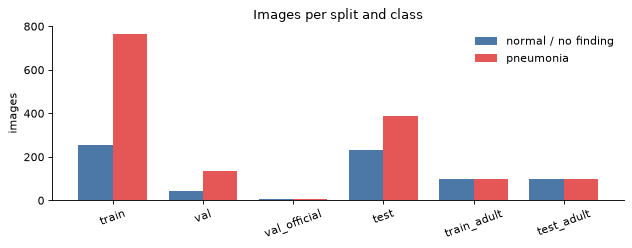

In [2]:
manifest = json.loads((DATA / "manifest.json").read_text())

SPLITS = ["train", "val", "val_official", "test", "train_adult", "test_adult"]
paths, labels = {}, {}
for s in SPLITS:
    rows = [m for m in manifest if m["split"] == s]
    paths[s] = [m["path"] for m in rows]
    labels[s] = np.array([1 if m["label"] == "pneumonia" else 0 for m in rows])    # 1 = pneumonia

print(f"{'split':14s}{'normal':>8s}{'pneumonia':>11s}{'total':>7s}   share pneumonia")
for s in SPLITS:
    n1 = int(labels[s].sum()); n0 = len(labels[s]) - n1
    print(f"{s:14s}{n0:8d}{n1:11d}{n0 + n1:7d}   {n1 / (n0 + n1):.1%}")

fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(SPLITS)); wd = 0.38
ax.bar(x - wd / 2, [int((labels[s] == 0).sum()) for s in SPLITS], wd, label="normal / no finding", color="#4C78A8")
ax.bar(x + wd / 2, [int((labels[s] == 1).sum()) for s in SPLITS], wd, label="pneumonia", color="#E45756")
ax.set_xticks(x); ax.set_xticklabels(SPLITS, rotation=20); ax.set_ylabel("images"); ax.legend(frameon=False)
ax.set_title("Images per split and class")
plt.tight_layout(); plt.show()

The Kermany splits are about 3 pneumonia images for every normal one. That is the class imbalance the workshop starts from. A model that always says "pneumonia" is right 62.5% of the time on the Kermany test set, so any score has to be read against that.

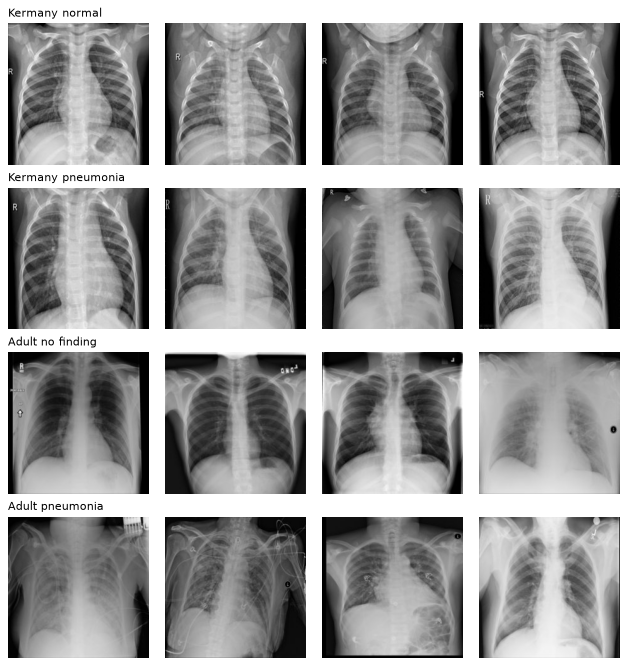

In [3]:
def load_rgb(rel_path):
    # Load one image as a float32 array in [0, 1] with shape (224, 224, 3).
    return np.asarray(Image.open(DATA / rel_path).convert("RGB"), dtype=np.float32) / 255.0

rng = np.random.default_rng(SEED)
rows = [("train", 0, "Kermany normal"), ("train", 1, "Kermany pneumonia"),
        ("test_adult", 0, "Adult no finding"), ("test_adult", 1, "Adult pneumonia")]
fig, axes = plt.subplots(len(rows), 4, figsize=(8, 8.4))
for r, (split, cls, title) in enumerate(rows):
    idx = rng.choice(np.flatnonzero(labels[split] == cls), size=4, replace=False)
    for c, i in enumerate(idx):
        axes[r, c].imshow(load_rgb(paths[split][i]), cmap="gray"); axes[r, c].axis("off")
    axes[r, 0].set_title(title, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

Look at the difference between the rows. The adult images are framed differently, exposed differently and come from other machines. A model trained only on the children's images has never seen anything like them.

## 2. Features from a frozen network

We do not train a network from scratch. We take MobileNetV3-Large that was already trained on ImageNet (everyday photos), cut off its classifier, and use what is left as a feature extractor:

`image -> convolutional layers -> 960 feature maps of 7 x 7 -> average over the 7 x 7 -> 960 numbers`

"Frozen" means we never change its weights. It is in `eval` mode (no dropout, fixed batch-norm statistics), and we run it under `torch.no_grad()` because we do not need gradients here. Pixel values are scaled to 0 to 1 and then normalised with the ImageNet mean and standard deviation, which is what the network was trained with.

**Network access.** The first time this runs, torchvision downloads the weights (about 21 MB) into its cache. After that everything works offline. If you are offline and the weights are missing, the cell below prints where to put the file.

In [4]:
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights

WEIGHTS = MobileNet_V3_Large_Weights.IMAGENET1K_V1
try:
    net = mobilenet_v3_large(weights=WEIGHTS)
except Exception as err:
    ckpt = Path(torch.hub.get_dir()) / "checkpoints" / Path(WEIGHTS.url).name
    print("Could not download the MobileNetV3 weights (are you offline?).")
    print("Download this file on a machine with internet:\n  ", WEIGHTS.url)
    print("and copy it to:\n  ", ckpt)
    print("Then run this cell again. Original error:", repr(err))
    raise

net = net.to(DEVICE).eval()
for p in net.parameters():
    p.requires_grad_(False)

backbone = net.features                      # image -> (n, 960, 7, 7); the classifier is not used
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def to_input(batch01):
    # (n, 224, 224, 3) float array in [0, 1] -> normalised tensor (n, 3, 224, 224)
    x = torch.from_numpy(np.ascontiguousarray(batch01, dtype=np.float32)).permute(0, 3, 1, 2)
    return (x - MEAN) / STD

@torch.no_grad()
def feature_maps(batch01):
    # Last convolutional output, (n, 960, 7, 7).
    return backbone(to_input(batch01))

@torch.no_grad()
def embed(batch01):
    # Global average pooling over the 7 x 7 grid -> (n, 960).
    return feature_maps(batch01).mean(dim=(2, 3)).numpy()

one = load_rgb(paths["train"][0])[None]
print("feature map:", tuple(feature_maps(one).shape), "-> pooled:", embed(one).shape)

feature map: (1, 960, 7, 7) -> pooled: (1, 960)


The helper below turns a list of image paths into a feature matrix, 32 images at a time. It accepts an optional `transform` (a function from image to image) so we can later stamp or degrade the images before the network sees them. Results are saved to `.cache/`, so a rerun does not recompute them. Delete the folder to force a fresh extraction.

In [5]:
def features_for(rel_paths, transform=None, batch_size=32):
    out = []
    for i in range(0, len(rel_paths), batch_size):
        imgs = [load_rgb(p) for p in rel_paths[i:i + batch_size]]
        if transform is not None:
            imgs = [transform(im) for im in imgs]
        out.append(embed(np.stack(imgs)))
    return np.concatenate(out)

def cached_features(name, rel_paths, transform=None):
    f = CACHE / f"mnv3l_v1_{name}.npy"
    if f.exists():
        x = np.load(f)
        if len(x) == len(rel_paths):
            print(f"{name:26s}{len(x):5d} images  (from cache)")
            return x
    t0 = time.perf_counter()
    x = features_for(rel_paths, transform)
    np.save(f, x)
    dt = time.perf_counter() - t0
    TIMES["extraction"] = TIMES.get("extraction", 0.0) + dt
    print(f"{name:26s}{len(x):5d} images  {dt:5.1f} s  ({len(x) / dt:.0f} images/s)")
    return x

X = {}
with timed("clean features"):
    for s in SPLITS:
        X[s] = cached_features(s, paths[s])
print("feature matrix for train:", X["train"].shape)

train                      1020 images    6.6 s  (154 images/s)


val                         180 images    1.4 s  (129 images/s)
val_official                 16 images    0.1 s  (130 images/s)


test                        624 images    4.6 s  (137 images/s)


train_adult                 200 images    1.4 s  (145 images/s)


test_adult                  200 images    1.3 s  (150 images/s)
[clean features] 15.4 s
feature matrix for train: (1020, 960)


Each X-ray is now 960 numbers. The rest of the notebook only trains small models on those numbers, which takes a second or two.

## 3. Train a logistic regression and score it

Logistic regression is the same model as the "head" in the web app: one weight per feature, added up, squashed to a probability of pneumonia. We train two versions on the Kermany `train` split:

- **realistic**: the training set as it is (3 pneumonia for every normal),
- **balanced**: `class_weight="balanced"`, which makes each normal image count three times as much, so both classes carry equal weight.

First we need the metrics. Positive means pneumonia.

- **sensitivity**: of the sick children, how many did we catch,
- **specificity**: of the healthy children, how many did we clear,
- **balanced accuracy**: the average of the two (so "always pneumonia" gets exactly 50%),
- **confusion matrix**: the four counts behind them.

In [6]:
def scores(y, pred):
    y, pred = np.asarray(y), np.asarray(pred)
    tp = int(((y == 1) & (pred == 1)).sum()); fn = int(((y == 1) & (pred == 0)).sum())
    tn = int(((y == 0) & (pred == 0)).sum()); fp = int(((y == 0) & (pred == 1)).sum())
    sens = tp / (tp + fn) if tp + fn else float("nan")
    spec = tn / (tn + fp) if tn + fp else float("nan")
    return dict(n=len(y), acc=(tp + tn) / len(y), sens=sens, spec=spec, bal=(sens + spec) / 2,
                tp=tp, fn=fn, tn=tn, fp=fp)

def baseline(y):
    # "Always pneumonia": the score to beat.
    return scores(y, np.ones(len(y), dtype=int))

def predict(clf, Xs, threshold=0.5):
    return (clf.predict_proba(Xs)[:, 1] >= threshold).astype(int)

def report(title, y, pred):
    s = scores(y, pred); b = baseline(y)
    print(f"{title}  (n={s['n']})")
    print(f"  accuracy {s['acc']:.1%}   sensitivity {s['sens']:.1%}   specificity {s['spec']:.1%}   "
          f"balanced accuracy {s['bal']:.1%}")
    print(f"  confusion matrix    predicted normal | predicted pneumonia")
    print(f"    truly normal         {s['tn']:5d}       |      {s['fp']:5d}")
    print(f"    truly pneumonia      {s['fn']:5d}       |      {s['tp']:5d}")
    print(f"  always-pneumonia baseline: accuracy {b['acc']:.1%}, balanced accuracy {b['bal']:.1%}")
    return s

def fit(Xtr, ytr, balanced=False, C=1.0):
    clf = LogisticRegression(C=C, class_weight="balanced" if balanced else None,
                             max_iter=5000, random_state=SEED)
    return clf.fit(Xtr, ytr)

with timed("fit realistic + balanced"):
    clf_real = fit(X["train"], labels["train"], balanced=False)
    clf_bal = fit(X["train"], labels["train"], balanced=True)
print("training accuracy (realistic):", f"{clf_real.score(X['train'], labels['train']):.1%}")

[fit realistic + balanced] 0.1 s
training accuracy (realistic): 99.9%


### The stress set

The web app's "Kermany stress" set is the Kermany test set with one fixed, mild degradation: brightness -0.2, contrast x0.8, a 95% centre crop resized back, and a 5 degree rotation with black fill. The order matters and follows the app's `pixelOps.js`: contrast around the image mean, then brightness, clip to 0 to 1, then crop, then rotate, then clip. Same patients, same labels, only worse picture quality.

test_stress                 624 images   12.1 s  (52 images/s)


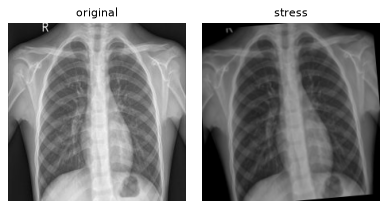

In [7]:
STRESS_PRESET = dict(brightness=-0.2, contrast=0.8, rotation_deg=5.0, crop_frac=0.95)

def perturb(img, brightness=0.0, contrast=1.0, rotation_deg=0.0, crop_frac=1.0):
    # Same steps and order as the web app: contrast, brightness, clip, crop, rotate, clip.
    # img: float32 (h, w, 3) in [0, 1].
    x = img.astype(np.float32).copy()
    h, w = x.shape[:2]
    if contrast != 1.0:
        m = x.mean()
        x = (x - m) * contrast + m
    if brightness != 0.0:
        x = x + brightness
    x = np.clip(x, 0.0, 1.0)
    yy, xx = np.meshgrid(np.arange(h, dtype=np.float64), np.arange(w, dtype=np.float64), indexing="ij")
    if crop_frac < 1.0:
        f = min(1.0, max(0.05, crop_frac))
        lo = (1 - f) / 2
        # output pixel i samples the input at lo*(size-1) + i*f (bilinear), like tf.image.cropAndResize
        x = np.stack([map_coordinates(x[..., c], [lo * (h - 1) + yy * f, lo * (w - 1) + xx * f],
                                      order=1, mode="nearest") for c in range(3)], axis=-1)
    if rotation_deg != 0.0:
        th = np.deg2rad(rotation_deg)
        cy, cx = (h - 1) / 2, (w - 1) / 2
        src_x = np.cos(th) * (xx - cx) - np.sin(th) * (yy - cy) + cx      # picture turns counter-clockwise
        src_y = np.sin(th) * (xx - cx) + np.cos(th) * (yy - cy) + cy
        x = np.stack([map_coordinates(x[..., c], [src_y, src_x], order=1, mode="grid-constant", cval=0.0)
                      for c in range(3)], axis=-1)
    return np.clip(x, 0.0, 1.0).astype(np.float32)

def stress(img):
    return perturb(img, **STRESS_PRESET)

X["test_stress"] = cached_features("test_stress", paths["test"], transform=stress)
labels["test_stress"] = labels["test"]

fig, axes = plt.subplots(1, 2, figsize=(5, 2.6))
sample = load_rgb(paths["test"][0])
axes[0].imshow(sample, cmap="gray", vmin=0, vmax=1); axes[0].set_title("original", fontsize=10)
axes[1].imshow(stress(sample), cmap="gray", vmin=0, vmax=1); axes[1].set_title("stress", fontsize=10)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

Now score both models on the four evaluation sets. The validation set comes from the same distribution as the training set, so expect it to look good.

In [8]:
EVAL_SETS = [("val", "Kermany val"), ("test", "Kermany test"), ("test_adult", "Adult test"), ("test_stress", "Kermany stress")]

def results_table(models):
    # models: {name: classifier}. Prints one small table per metric and returns all the numbers.
    table = {m: {s: scores(labels[s], predict(clf, X[s])) for s, _ in EVAL_SETS} for m, clf in models.items()}
    head = f"{'':22s}" + "".join(f"{title:>16s}" for _, title in EVAL_SETS)
    for metric, name in [("acc", "accuracy"), ("sens", "sensitivity"), ("spec", "specificity"), ("bal", "balanced accuracy")]:
        print(name); print(head)
        for mname in models:
            print(f"  {mname:20s}" + "".join(f"{table[mname][s][metric]:16.1%}" for s, _ in EVAL_SETS))
        if metric == "acc":
            print(f"  {'always pneumonia':20s}" + "".join(f"{baseline(labels[s])['acc']:16.1%}" for s, _ in EVAL_SETS))
        print()
    return table

table = results_table({"realistic": clf_real, "balanced": clf_bal})

accuracy
                           Kermany val    Kermany test      Adult test  Kermany stress
  realistic                      98.9%           84.0%           53.0%           79.5%
  balanced                       99.4%           86.7%           54.0%           80.9%
  always pneumonia               75.0%           62.5%           50.0%           62.5%

sensitivity
                           Kermany val    Kermany test      Adult test  Kermany stress
  realistic                     100.0%          100.0%           75.0%           99.5%
  balanced                      100.0%           99.5%           72.0%           98.7%

specificity
                           Kermany val    Kermany test      Adult test  Kermany stress
  realistic                      95.6%           57.3%           31.0%           46.2%
  balanced                       97.8%           65.4%           36.0%           51.3%

balanced accuracy
                           Kermany val    Kermany test      Adult test  Kerm

In [9]:
_ = report("Realistic model on the Kermany test set", labels["test"], predict(clf_real, X["test"]))
print()
_ = report("Realistic model on the adult test set", labels["test_adult"], predict(clf_real, X["test_adult"]))

Realistic model on the Kermany test set  (n=624)
  accuracy 84.0%   sensitivity 100.0%   specificity 57.3%   balanced accuracy 78.6%
  confusion matrix    predicted normal | predicted pneumonia
    truly normal           134       |        100
    truly pneumonia          0       |        390
  always-pneumonia baseline: accuracy 62.5%, balanced accuracy 50.0%

Realistic model on the adult test set  (n=200)
  accuracy 53.0%   sensitivity 75.0%   specificity 31.0%   balanced accuracy 53.0%
  confusion matrix    predicted normal | predicted pneumonia
    truly normal            31       |         69
    truly pneumonia         25       |         75
  always-pneumonia baseline: accuracy 50.0%, balanced accuracy 50.0%


Read these against the web app's numbers (about 82% accuracy, 99.5% sensitivity and 54% specificity on the Kermany test set; barely above chance on the adult set). The pattern is what matters:

- Validation accuracy is very high, because validation looks like training.
- On the real test set the model catches nearly all sick children but clears only a little over half of the healthy ones. Part of its accuracy is just the 62.5% you get from saying "pneumonia" a lot.
- On the adult images it is close to a coin flip.
- The stress set costs it accuracy and specificity even though the labels and patients did not change. In the web app the same degradation hurts more than it does here (about 61% balanced accuracy there). MobileNetV3 happens to be a bit more tolerant of it than MobileNet v2, which is a reminder that robustness belongs to a particular model, not to the task.

## 4. Class imbalance

With three pneumonia images for every normal one, the cheapest way to lower the training loss is to lean towards "pneumonia". Re-weighting the classes (`class_weight="balanced"`) tells the model that a missed normal image costs as much as a missed pneumonia image. Compare the two models on the two real test sets.

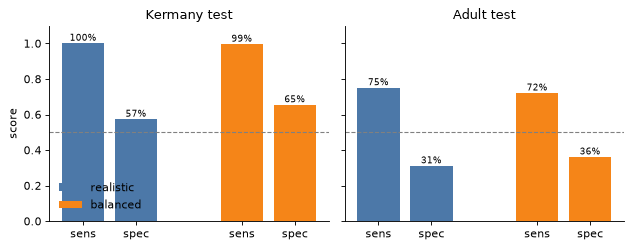

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), sharey=True)
for ax, (s, title) in zip(axes, [("test", "Kermany test"), ("test_adult", "Adult test")]):
    for k, (mname, color) in enumerate([("realistic", "#4C78A8"), ("balanced", "#F58518")]):
        sc = table[mname][s]
        bars = ax.bar([k * 3, k * 3 + 1], [sc["sens"], sc["spec"]], color=color, label=mname)
        for b, v in zip(bars, [sc["sens"], sc["spec"]]):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.0%}", ha="center", fontsize=8)
    ax.axhline(0.5, color="grey", lw=1, ls="--")
    ax.set_xticks([0, 1, 3, 4]); ax.set_xticklabels(["sens", "spec", "sens", "spec"])
    ax.set_title(title); ax.set_ylim(0, 1.1)
axes[0].set_ylabel("score"); axes[0].legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

Balancing moves the model along the sensitivity/specificity trade-off: fewer healthy children are flagged, a few more sick ones are missed. It does not make the model better at telling the two apart. Whether that trade is good depends on what a missed case costs compared with a false alarm, which is a question about the clinic, not about the code. And on the adult images re-weighting does little, because the problem there is a different one (section 6).

## 5. The stamp shortcut

Now we cheat on purpose. We draw a small white box with a black letter R in the top-left corner of **every pneumonia training image** and no normal image. A model that wants to separate the classes now has an easy extra clue that has nothing to do with lungs.

The stamp below follows the web app's geometry exactly: a 5 x 7 pixel letter R, scaled with nearest-neighbour sampling into a square box of `size` pixels (default 48) with a one-cell margin, placed 8 pixels from the top-left corner, opacity 1.

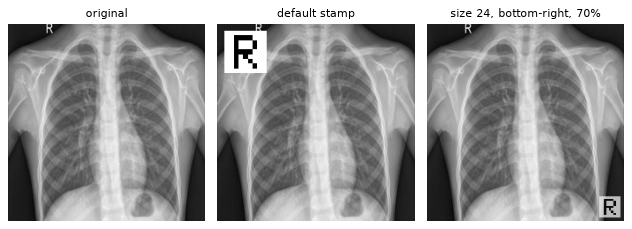

In [11]:
R_GLYPH = ["####.",
           "#...#",
           "#...#",
           "####.",
           "#.#..",
           "#..#.",
           "#...#"]
DEFAULT_STAMP = dict(size=48, position="top-left", offset_x=8, offset_y=8, opacity=1.0)

def stamp_mask(size=48, position="top-left", offset_x=8, offset_y=8, opacity=1.0, h=224, w=224):
    # Returns (alpha, color), both (h, w): opacity inside the box, and 1 = white box / 0 = black ink.
    size = int(min(96, max(8, np.floor(size + 0.5))))
    opacity = float(min(1.0, max(0.0, opacity)))
    x0 = offset_x if position.endswith("left") else w - size - offset_x
    y0 = offset_y if position.startswith("top") else h - size - offset_y
    cell = size / 9                           # 7 glyph rows + 1 cell of margin above and below
    x_inset = (size - 7 * cell) / 2           # 5 glyph columns + 1 cell of margin each side, centred
    alpha = np.zeros((h, w)); color = np.zeros((h, w))
    ys = np.arange(max(0, y0), min(h, y0 + size)); xs = np.arange(max(0, x0), min(w, x0 + size))
    gy = np.floor((ys - y0 + 0.5) / cell).astype(int) - 1
    gx = np.floor((xs - x0 + 0.5 - x_inset) / cell).astype(int) - 1
    glyph = np.array([[c == "#" for c in row] for row in R_GLYPH])
    ink = np.zeros((len(ys), len(xs)), dtype=bool)
    ok_r = (gy >= 0) & (gy < 7); ok_c = (gx >= 0) & (gx < 5)
    ink[np.ix_(ok_r, ok_c)] = glyph[np.ix_(gy[ok_r], gx[ok_c])]
    alpha[np.ix_(ys, xs)] = opacity
    color[np.ix_(ys, xs)] = np.where(ink, 0.0, 1.0)
    return alpha, color

def apply_stamp(img, **cfg):
    # Blend the stamp into an image (float32, h x w x 3, [0, 1]). Pixels outside the box are untouched.
    cfg = {**DEFAULT_STAMP, **cfg}
    alpha, color = stamp_mask(h=img.shape[0], w=img.shape[1], **cfg)
    a, c = alpha[..., None], color[..., None]
    return (img * (1 - a) + c * a).astype(np.float32)

def stamper(**cfg):
    return lambda img: apply_stamp(img, **cfg)

fig, axes = plt.subplots(1, 3, figsize=(8, 2.8))
sample = load_rgb(paths["test"][0])
axes[0].imshow(sample, cmap="gray", vmin=0, vmax=1); axes[0].set_title("original", fontsize=10)
axes[1].imshow(apply_stamp(sample), cmap="gray", vmin=0, vmax=1); axes[1].set_title("default stamp", fontsize=10)
axes[2].imshow(apply_stamp(sample, size=24, position="bottom-right", offset_x=4, offset_y=4, opacity=0.7),
               cmap="gray", vmin=0, vmax=1); axes[2].set_title("size 24, bottom-right, 70%", fontsize=10)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

Now the experiment, written as a function so you can call it with other stamp settings later:

1. extract features of the **stamped** pneumonia training images (the normal ones stay clean),
2. train the same realistic model on that doctored training set,
3. stamp the **normal** test images and see how often the prediction changes (the flip rate),
4. check what happened to the clean pneumonia images.

We run each measurement for the normal model ("before") and the stamp-trained model ("after").

In [12]:
def stamp_name(cfg):
    c = {**DEFAULT_STAMP, **cfg}
    return f"s{c['size']}_{c['position']}_{c['offset_x']}_{c['offset_y']}_{int(round(c['opacity'] * 100))}"

def stamp_experiment(cfg=None, verbose=True):
    cfg = cfg or {}
    tag = stamp_name(cfg)
    pneu_tr = np.flatnonzero(labels["train"] == 1)
    X_tr_pneu = cached_features(f"train_pneu_{tag}", [paths["train"][i] for i in pneu_tr], stamper(**cfg))
    X_test_st = cached_features(f"test_{tag}", paths["test"], stamper(**cfg))

    X_stamped_train = X["train"].copy()
    X_stamped_train[pneu_tr] = X_tr_pneu                       # only pneumonia images get the stamp
    clf_stamp = fit(X_stamped_train, labels["train"])

    y = labels["test"]; normal = y == 0
    out = {}
    for name, clf in [("before (normal model)", clf_real), ("after (stamp-trained)", clf_stamp)]:
        clean = predict(clf, X["test"]); stamped = predict(clf, X_test_st)
        sc = scores(y, clean)
        out[name] = dict(
            normal_clean=clean[normal].mean(),                 # share of normal images called pneumonia, clean
            normal_stamped=stamped[normal].mean(),             # ... and when stamped
            flip_normal=(clean[normal] != stamped[normal]).mean(),
            sens_clean=sc["sens"], spec_clean=sc["spec"], acc_clean=sc["acc"],
        )
    if verbose:
        print(f"stamp: {cfg or 'default'}   (rates are over the {int(normal.sum())} normal test images, "
              f"sensitivity over the {int((~normal).sum())} clean pneumonia test images)")
        print(f"{'':24s}{'called pneumonia':>18s}{'called pneumonia':>18s}{'flip rate':>11s}{'sensitivity':>13s}")
        print(f"{'':24s}{'(clean)':>18s}{'(stamped)':>18s}{'(stamped)':>11s}{'(clean)':>13s}")
        for name, o in out.items():
            print(f"{name:24s}{o['normal_clean']:18.1%}{o['normal_stamped']:18.1%}{o['flip_normal']:11.1%}{o['sens_clean']:13.1%}")
    return out, clf_stamp, X_test_st

with timed("stamp experiment"):
    stamp_out, clf_stamp, X_test_stamped = stamp_experiment()

train_pneu_s48_top-left_8_8_100  765 images    6.4 s  (119 images/s)


test_s48_top-left_8_8_100   624 images    5.3 s  (117 images/s)
stamp: default   (rates are over the 234 normal test images, sensitivity over the 390 clean pneumonia test images)
                          called pneumonia  called pneumonia  flip rate  sensitivity
                                   (clean)         (stamped)  (stamped)      (clean)
before (normal model)                42.7%             61.5%      20.5%       100.0%
after (stamp-trained)                 3.4%             99.6%      96.2%        28.2%
[stamp experiment] 11.8 s


What to read from this:

- The normal model is moved a little by the stamp (a bright white box is an odd thing to see in a corner), but it was never taught that the stamp means anything.
- The stamp-trained model calls nearly every stamped normal X-ray pneumonia, and nearly every clean normal X-ray normal. The stamp has become the strongest clue it has.
- Look at the clean pneumonia images: with the shortcut available, the model relies less on the lungs, so it misses sick children it used to catch (sensitivity falls a lot). That drop on unstamped images is the sign that it learned the marker and not the disease. The web app shows the same pattern, with a flip rate around 94%.
- On its own training data this model looks fine. You only see the problem by testing with the marker moved around, which is what the web app's stamp tab does.

Real data has stamps like this too: a hospital tag, a scanner label, a "portable" marker, a pen mark. If one clinic sends more sick patients, any mark that identifies the clinic is a shortcut.

## 6. Population shift and the worst-case score

The adult test set asks a different question: does the model still work on a different population? Its images come from adults at another hospital, on other machines, labeled from text reports.

One fix is to mix some adult images into training. We have 200 balanced adult images set aside for that (`train_adult`, separate from `test_adult`). We compare three models:

1. **realistic**: Kermany train as is,
2. **balanced**: same data, class weights,
3. **balanced + adult mix**: Kermany train plus the 200 adult training images, class weights.

The score to compare them is the **worst-case score**: the lowest balanced accuracy over three sets (Kermany test, adult test, Kermany stress). A model is only as good as the set it handles worst. Balanced accuracy is the threshold-free version of the web app's half-credit score: with no "refer to a doctor" option, they are the same number.

[fit adult mix] 0.1 s
balanced accuracy           Kermany test      Adult test  Kermany stress    worst case
realistic                          78.6%           53.0%           72.8%         53.0%
balanced                           82.4%           54.0%           75.0%         54.0%
balanced + adult mix               77.3%           62.5%           82.1%         62.5%
always pneumonia                   50.0%           50.0%           50.0%         50.0%


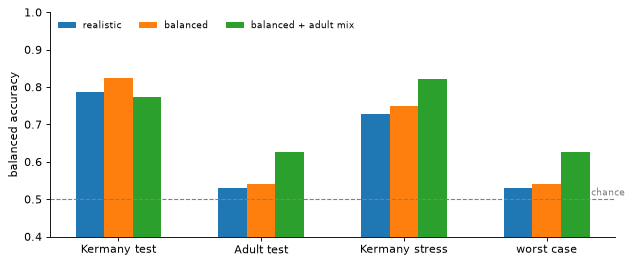

In [13]:
X_mix = np.concatenate([X["train"], X["train_adult"]])
y_mix = np.concatenate([labels["train"], labels["train_adult"]])
with timed("fit adult mix"):
    clf_mix = fit(X_mix, y_mix, balanced=True)

WORST_SETS = [("test", "Kermany test"), ("test_adult", "Adult test"), ("test_stress", "Kermany stress")]
models = {"realistic": clf_real, "balanced": clf_bal, "balanced + adult mix": clf_mix}

worst = {}
print(f"{'balanced accuracy':24s}" + "".join(f"{t:>16s}" for _, t in WORST_SETS) + f"{'worst case':>14s}")
for mname, clf in models.items():
    bal = [scores(labels[s], predict(clf, X[s]))["bal"] for s, _ in WORST_SETS]
    worst[mname] = (bal, min(bal))
    print(f"{mname:24s}" + "".join(f"{v:16.1%}" for v in bal) + f"{min(bal):14.1%}")
print(f"{'always pneumonia':24s}" + "".join(f"{0.5:16.1%}" for _ in WORST_SETS) + f"{0.5:14.1%}")

fig, ax = plt.subplots(figsize=(8, 3.4))
wd = 0.2; x = np.arange(len(WORST_SETS) + 1)
for k, (mname, (bal, w)) in enumerate(worst.items()):
    ax.bar(x + (k - 1) * wd, bal + [w], wd, label=mname)
ax.axhline(0.5, color="grey", lw=1, ls="--"); ax.text(len(x) - 0.45, 0.51, "chance", color="grey", fontsize=8, ha="right")
ax.set_xticks(x); ax.set_xticklabels([t for _, t in WORST_SETS] + ["worst case"]); ax.set_ylim(0.4, 1.0)
ax.set_ylabel("balanced accuracy"); ax.legend(frameon=False, fontsize=8, loc="upper left", ncol=3)
plt.tight_layout(); plt.show()

The worst case is the adult set for the first two models, so that is where the score moves when we show the model a few adult images. Compare with the web app, where the same kind of fix lifts the worst-case score from about 51 to about 59. The fix helps, but the model is still far from good on adults, and 200 images from one source are a small sample of "adults". Also look at what the fix costs on the other sets: here the Kermany test score drops by a few points. A fix that raises the worst case and quietly lowers the best case is still a trade, and you should look at both.

## 7. Grad-CAM: where is the model looking?

Grad-CAM colours the image regions that pushed the prediction towards a class. The recipe:

1. take the last convolutional output `A` (960 maps of 7 x 7, the output of `net.features`),
2. for each map `k`, ask how much the pneumonia score would change if that map got bigger: the gradient averaged over the 7 x 7 grid gives a weight `alpha_k`,
3. add up the maps with those weights and keep only the positive part: `CAM = ReLU(sum_k alpha_k * A_k)`,
4. stretch the 7 x 7 result up to the image size and lay it over the picture.

**A shortcut for a linear head.** Our classifier is a linear function of the *pooled* features: `logit = sum_k w_k * mean_hw(A_k) + b`. The gradient of the logit with respect to every cell of map `k` is just `w_k / (7*7)`, so `alpha_k = w_k / 49` and

`CAM = ReLU(sum_k w_k * A_k) / 49`

No backpropagation is needed. For a linear head, Grad-CAM and the older CAM method are the same thing. The cell below checks the formula against real autograd on one image.

In [14]:
def cam_linear(coef, fmap):
    # fmap: (960, 7, 7) array; coef: (960,) weights of the logistic regression -> (7, 7) CAM
    return np.maximum(np.tensordot(coef, fmap, axes=(0, 0)) / (fmap.shape[1] * fmap.shape[2]), 0.0)

def cam_autograd(clf, img01):
    # The textbook way: gradient of the logit w.r.t. the feature map, averaged over space, used as weights.
    w = torch.tensor(clf.coef_[0], dtype=torch.float32)
    b = float(clf.intercept_[0])
    A = backbone(to_input(img01[None])).detach().requires_grad_(True)       # (1, 960, 7, 7)
    logit = (A.mean(dim=(2, 3)) * w).sum() + b
    (grad,) = torch.autograd.grad(logit, A)
    alpha = grad.mean(dim=(2, 3), keepdim=True)                              # (1, 960, 1, 1)
    return torch.relu((alpha * A).sum(dim=1))[0].detach().numpy()

img = load_rgb(paths["test"][0])
a = cam_linear(clf_real.coef_[0], feature_maps(img[None])[0].numpy())
b = cam_autograd(clf_real, img)
print("closed form equals autograd Grad-CAM:", np.allclose(a, b, atol=1e-5), "| max abs difference", float(np.abs(a - b).max()))

closed form equals autograd Grad-CAM: True | max abs difference 8.940696716308594e-08


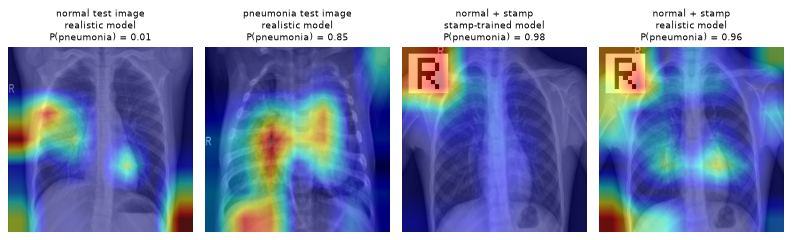

In [15]:
def heatmap(clf, img):
    # CAM upsampled to image size and scaled to 0..1 (relative to this image's own maximum).
    fmap = feature_maps(img[None])[0].numpy()
    cam = cam_linear(clf.coef_[0], fmap)
    big = F.interpolate(torch.from_numpy(cam)[None, None].float(), size=img.shape[:2], mode="bilinear",
                        align_corners=False)[0, 0].numpy()
    return cam, big / (big.max() + 1e-9)

def pick(mask, k=0):
    return int(np.flatnonzero(mask)[k])

y_test = labels["test"]
p_real = clf_real.predict_proba(X["test"])[:, 1]
p_stamp_on_stamped = clf_stamp.predict_proba(X_test_stamped)[:, 1]

i_normal = pick((y_test == 0) & (p_real < 0.5))                    # a normal image the model gets right
i_pneu = pick((y_test == 1) & (p_real >= 0.5))                     # a pneumonia image the model gets right
i_stamped = pick((y_test == 0) & (p_stamp_on_stamped >= 0.5))      # a normal image the stamp model now calls pneumonia

panels = [
    ("normal test image\nrealistic model", clf_real, load_rgb(paths["test"][i_normal])),
    ("pneumonia test image\nrealistic model", clf_real, load_rgb(paths["test"][i_pneu])),
    ("normal + stamp\nstamp-trained model", clf_stamp, apply_stamp(load_rgb(paths["test"][i_stamped]))),
    ("normal + stamp\nrealistic model", clf_real, apply_stamp(load_rgb(paths["test"][i_stamped]))),
]
fig, axes = plt.subplots(1, 4, figsize=(10, 3.2))
for ax, (title, clf, im) in zip(axes, panels):
    _, hm = heatmap(clf, im)
    p = clf.predict_proba(embed(im[None]))[0, 1]
    ax.imshow(im, cmap="gray", vmin=0, vmax=1); ax.imshow(hm, cmap="jet", alpha=0.5, vmin=0, vmax=1)
    ax.set_title(f"{title}\nP(pneumonia) = {p:.2f}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

One example proves nothing, so count instead. The stamp sits in the top-left corner and covers the cells in rows 0 to 1 and columns 0 to 1 of the 7 x 7 map. For all 234 stamped normal test images, how often is the brightest cell of the heatmap inside the stamp?

In [16]:
def peak_in_stamp(clf, indices):
    hits = 0
    for i in indices:
        cam, _ = heatmap(clf, apply_stamp(load_rgb(paths["test"][i])))
        r, c = np.unravel_index(np.argmax(cam), cam.shape)
        hits += int(r <= 1 and c <= 1)
    return hits / len(indices)

normals = np.flatnonzero(y_test == 0)
with timed("peak-in-stamp count"):
    print(f"stamp-trained model: heatmap peak inside the stamp for {peak_in_stamp(clf_stamp, normals):.0%} of stamped normal images")
    print(f"realistic model:     heatmap peak inside the stamp for {peak_in_stamp(clf_real, normals):.0%} of stamped normal images")
    print(f"for scale: the stamp covers 4 of 49 cells = {4 / 49:.0%} of the map")

stamp-trained model: heatmap peak inside the stamp for 100% of stamped normal images


realistic model:     heatmap peak inside the stamp for 62% of stamped normal images
for scale: the stamp covers 4 of 49 cells = 8% of the map
[peak-in-stamp count] 7.6 s


The shortcut model's heatmap peaks on the stamp for essentially every image, which is what we hoped to see. The realistic model peaks there often too, because a bright white box is a strong pattern for any network, so a peak on the stamp alone does not say the model *relies* on it. The flip rate from section 5 does that.

**How much to trust a heatmap.** Treat it as a hint, not proof.

- The map is only 7 x 7 and blown up, so it is blurry. It cannot outline a lesion.
- It shows what *pushed this score up*, not what a doctor would call the cause. A model can look at the right place for the wrong reason, or at the wrong place and still be right.
- It is relative: each image is scaled to its own maximum, so a bright patch on a confidently normal image still shows a peak.
- It can be useful for *finding* a shortcut, as with the stamp. It is not a way to *certify* that a model is safe.

## 8. Your turn

Five short challenges. Each starts from helpers defined above. Cells marked "slow" are commented out so the notebook stays quick; remove the `#` signs to run them.

**1. The smallest stamp that still fools the model.** `stamp_experiment(dict(size=...))` runs the whole shortcut experiment for other settings (size 8 to 96, position, offsets, opacity). Find the smallest size where the flip rate stays high. Then try a faint stamp with `opacity=0.3`, or move it to the bottom-right corner. Each new setting needs about 1,000 feature extractions, so expect up to half a minute.

In [17]:
# slow: roughly 10 to 30 seconds per setting
# for size in [8, 16, 24, 32]:
#     out, _, _ = stamp_experiment(dict(size=size), verbose=False)
#     print(size, f"flip rate on normal test images: {out['after (stamp-trained)']['flip_normal']:.0%}")

**2. Regularisation.** `C` is the inverse of the regularisation strength: a small `C` keeps the weights small and the model simple, a large `C` lets it fit the training set closely. Try other values and watch the Kermany and adult scores, not just training accuracy. Which `C` gives the best worst-case score?

In [18]:
for C in [0.0003, 0.003, 0.03, 0.3, 3.0]:
    clf = fit(X["train"], labels["train"], balanced=True, C=C)
    bal = [scores(labels[s], predict(clf, X[s]))["bal"] for s, _ in WORST_SETS]
    print(f"C={C:<8g} train acc {clf.score(X['train'], labels['train']):.1%}   balanced accuracy: "
          + "  ".join(f"{t} {v:.1%}" for (_, t), v in zip(WORST_SETS, bal)) + f"   worst {min(bal):.1%}")

C=0.0003   train acc 85.4%   balanced accuracy: Kermany test 80.5%  Adult test 49.5%  Kermany stress 73.0%   worst 49.5%
C=0.003    train acc 91.1%   balanced accuracy: Kermany test 83.5%  Adult test 52.0%  Kermany stress 70.2%   worst 52.0%
C=0.03     train acc 96.7%   balanced accuracy: Kermany test 83.5%  Adult test 54.0%  Kermany stress 71.7%   worst 54.0%
C=0.3      train acc 99.1%   balanced accuracy: Kermany test 83.2%  Adult test 53.5%  Kermany stress 74.4%   worst 53.5%


C=3        train acc 100.0%   balanced accuracy: Kermany test 81.9%  Adult test 54.0%  Kermany stress 76.2%   worst 54.0%


**3. A hidden layer.** Swap the logistic regression for a small neural network with one hidden layer. Does the extra capacity help on the Kermany test set? Does it help on adults? `MLPClassifier` has no `class_weight`, so compare it with the *realistic* model.

In [19]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-2, max_iter=500, random_state=SEED)
with timed("mlp"):
    mlp.fit(X["train"], labels["train"])
for mname, clf in [("logistic (realistic)", clf_real), ("MLP, 64 hidden units", mlp)]:
    bal = [scores(labels[s], predict(clf, X[s]))["bal"] for s, _ in WORST_SETS]
    print(f"{mname:24s}" + "  ".join(f"{t} {v:.1%}" for (_, t), v in zip(WORST_SETS, bal)) + f"   worst {min(bal):.1%}")

[mlp] 1.3 s
logistic (realistic)    Kermany test 78.6%  Adult test 53.0%  Kermany stress 72.8%   worst 53.0%
MLP, 64 hidden units    Kermany test 76.6%  Adult test 53.0%  Kermany stress 72.8%   worst 53.0%


**4. Augmentation.** In the app, augmentation helps on the stress set by showing the model degraded copies of the training images. Do the same here: use `perturb` with random settings (brightness within plus or minus 0.3, contrast 0.7 to 1.3, rotation within 15 degrees, crop 0.8 to 1.0), extract features of those copies, add them to the training set, and re-score on the stress set. Hint: draw one set of random settings per image from `np.random.default_rng(SEED)` and pass it as the `transform` to `cached_features`.

In [20]:
# slow: about 15 seconds for 1,020 augmented copies
# rng = np.random.default_rng(SEED)
# def augment(img):
#     return perturb(img,
#                    brightness=rng.uniform(-0.3, 0.3),
#                    contrast=rng.uniform(0.7, 1.3),
#                    rotation_deg=rng.uniform(-15, 15),
#                    crop_frac=rng.uniform(0.8, 1.0))
# X_aug = cached_features("train_aug_v1", paths["train"], transform=augment)
# clf_aug = fit(np.concatenate([X["train"], X_aug]), np.concatenate([labels["train"]] * 2), balanced=True)
# print("stress balanced accuracy:", f"{scores(labels['test_stress'], predict(clf_aug, X['test_stress']))['bal']:.1%}",
#       "| before augmentation:", f"{table['balanced']['test_stress']['bal']:.1%}")

**5. Threshold and "refer to a doctor".** The model outputs a probability. We called everything at or above 0.5 pneumonia. Move that line and watch sensitivity and specificity trade places. Then add an abstain band: cases whose probability is close to 0.5 are referred to a human, and only the rest are scored. How wide can the band be before it refers most cases? Remember that referring everything gives the same 50% as always saying pneumonia, which is why the app counts a referral as half right.

In [21]:
p = clf_real.predict_proba(X["test"])[:, 1]; y = labels["test"]
print("threshold   sensitivity   specificity")
for thr in [0.3, 0.5, 0.7, 0.9, 0.97, 0.99]:
    s = scores(y, (p >= thr).astype(int))
    print(f"{thr:9.2f}{s['sens']:13.1%}{s['spec']:14.1%}")

print("\nband (refer if |p - 0.5| < band)   referred   accuracy on the rest")
for band in [0.0, 0.1, 0.2, 0.3, 0.4, 0.45]:
    keep = np.abs(p - 0.5) >= band
    acc = scores(y[keep], (p[keep] >= 0.5).astype(int))["acc"]
    print(f"{band:33.2f}{1 - keep.mean():10.1%}{acc:21.1%}")

threshold   sensitivity   specificity
     0.30       100.0%         47.0%
     0.50       100.0%         57.3%
     0.70        99.5%         68.4%
     0.90        96.7%         77.8%
     0.97        93.3%         85.9%
     0.99        87.4%         91.5%

band (refer if |p - 0.5| < band)   referred   accuracy on the rest
                             0.00      0.0%                84.0%
                             0.10      4.0%                85.3%
                             0.20      8.3%                87.1%
                             0.30     13.5%                87.6%
                             0.40     19.2%                89.7%
                             0.45     24.7%                90.9%


## What this notebook did not do

- It used one train/test split and one seed. The numbers would move a little with another sample; the web app's Repeat button shows how much.
- The Hugging Face copy of the Kermany data has no patient IDs, so the same child can appear in both train and validation. Validation is optimistic for that reason. The official test set is separate.
- The adult labels were mined from reports by software. Some are wrong.
- Nothing here has been checked for clinical use. It is a classroom exercise about how models fail.

In [22]:
print(f"feature extraction this run (zero if everything came from the cache): {TIMES.get('extraction', 0.0):.1f} s")
print("timed blocks (s):", {k: round(v, 1) for k, v in TIMES.items()})

feature extraction this run (zero if everything came from the cache): 39.3 s
timed blocks (s): {'extraction': 39.3, 'clean features': 15.4, 'fit realistic + balanced': 0.1, 'stamp experiment': 11.8, 'fit adult mix': 0.1, 'peak-in-stamp count': 7.6, 'mlp': 1.3}
